In [2]:
import numpy as np
import pandas as pd
import torch 
import torch.nn as nn
import matplotlib.pyplot as plt
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torchmetrics import MetricCollection, Accuracy, Precision, Recall, F1Score

In [3]:
df = pd.read_csv("diabetes_data.csv")
print(df.head())

   pregnancies  glucose  diastolic  triceps  insulin   bmi    dpf  age  \
0            6      148         72       35        0  33.6  0.627   50   
1            1       85         66       29        0  26.6  0.351   31   
2            8      183         64        0        0  23.3  0.672   32   
3            1       89         66       23       94  28.1  0.167   21   
4            0      137         40       35      168  43.1  2.288   33   

   diabetes  
0         1  
1         0  
2         1  
3         0  
4         1  


In [4]:
X = df.drop("diabetes", axis = 1)
y = df["diabetes"]

In [17]:
print(len(df))

768


In [5]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.22, random_state=42)

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [7]:
X_train_scaled_tensor = torch.tensor(X_train_scaled, dtype = torch.float32)
y_train_tensor = torch.tensor(y_train.values.reshape(-1,1), dtype=torch.float32)
X_val_scaled_tensor = torch.tensor(X_val_scaled, dtype = torch.float32)
y_val_tensor = torch.tensor(y_val.values.reshape(-1,1), dtype=torch.float32)
X_test_scaled_tensor = torch.tensor(X_test_scaled, dtype = torch.float32)
y_test_tensor = torch.tensor(y_test.values.reshape(-1,1), dtype=torch.float32)

input_dim = X.shape[1]
print(input_dim)

8


In [8]:
class MultiLayerPerceptronClassifier(nn.Module):
    def __init__(self, input_dim, activation_function = nn.ReLU):
        super(MultiLayerPerceptronClassifier, self).__init__()
        self.fc1 = nn.Linear(input_dim, 12)
        self.fc2 = nn.Linear(12, 8)
        self.output = nn.Linear(8, 2)
        self.activation_function = activation_function()
    def forward(self, x):
        x = self.activation_function(self.fc1(x))
        x = self.activation_function(self.fc2(x))
        x = self.output(x)
        return x
    

In [9]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0, restore_best_weights=True):
        self.patience = patience 
        self.min_delta = min_delta 
        self.restore_best_weights = restore_best_weights 
        self.best_loss = None
        self.counter = 0
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_model_state = model.state_dict()
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.best_model_state = model.state_dict()
            self.counter = 0

In [10]:
def perform_learning(epochs, optimizer_name, activation_function_name, early_stopping_enabled = True):
    activations = {'ReLU': nn.ReLU, 'Sigmoid': nn.Sigmoid, 'Tanh': nn.Tanh}
    activation_function = activations[activation_function_name]
    early_stopping = EarlyStopping()
    model = MultiLayerPerceptronClassifier(input_dim, activation_function)
    optimizers = {
    'SGD': optim.SGD(model.parameters(), lr=0.01),
    'RMSprop': optim.RMSprop(model.parameters(), lr=0.01),
    'Adam': optim.Adam(model.parameters(), lr=0.01),
    'Adadelta': optim.Adadelta(model.parameters(), lr=1.0),
    'Adagrad': optim.Adagrad(model.parameters(), lr=0.01),
    'Adamax': optim.Adamax(model.parameters(), lr=0.01),
    'Nadam': optim.NAdam(model.parameters(), lr=0.01)
    }
    criterion = nn.CrossEntropyLoss()    
    train_loss_history = []
    val_loss_history = []
    optimizer = optimizers[optimizer_name]
    metrics = MetricCollection({
        "accuracy": Accuracy(task="binary"),
        "precision": Precision(task="binary"),
        "recall": Recall(task="binary"),
        "f1": F1Score(task="binary")
    })
    already_stopped = False
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        train_logits = model(X_train_scaled_tensor)
        train_loss = criterion(train_logits, y_train_tensor.squeeze().long())
        train_loss.backward()
        optimizer.step()
        train_loss_history.append(train_loss.item())
        
        model.eval()
        metrics.reset()
        with torch.no_grad():
            val_logits = model(X_val_scaled_tensor)
            val_loss = criterion(val_logits, y_val_tensor.squeeze().long())
            val_probabilites = torch.softmax(val_logits, dim = 1)
            _, val_predictions = torch.max(val_probabilites, 1)
            if not already_stopped:
                step_metrics = metrics(val_predictions, y_val_tensor.squeeze().long())
            val_loss_history.append(val_loss.item())
            early_stopping(val_loss.item(), model)
        
        if early_stopping.early_stop and early_stopping_enabled and not already_stopped:
            print(f"--- [INFO] Early stopping triggered at epoch {epoch+1} for {optimizer_name} ---")
            already_stopped = True
            
        
        if((epoch + 1) % 50 == 0 and not early_stopping.early_stop):
            print(f'Optimizer: {optimizer_name}, Function: {activation_function_name}, Epoch [{epoch+1}/{epochs}], Train Loss: {train_loss.item():.4f}, Validation Loss: {val_loss.item():.4f}, Acc: {step_metrics["accuracy"]}',)
    
    if early_stopping.restore_best_weights:
        model.load_state_dict(early_stopping.best_model_state)
    
    return train_loss_history, val_loss_history, step_metrics, model

In [11]:
optimizer_names = ['SGD', 'RMSprop', 'Adam', 'Adadelta', 'Adagrad', 'Adamax', 'Nadam']
activation_function_names = ['ReLU', 'Sigmoid', 'Tanh']
results = []
best_model = None
best_f1 = 0

Optimizer: SGD, Function: ReLU, Epoch [50/1000], Train Loss: 0.6482, Validation Loss: 0.6567, Acc: 0.6405228972434998
Optimizer: SGD, Function: ReLU, Epoch [100/1000], Train Loss: 0.6316, Validation Loss: 0.6445, Acc: 0.6209150552749634
Optimizer: SGD, Function: ReLU, Epoch [150/1000], Train Loss: 0.6216, Validation Loss: 0.6371, Acc: 0.6209150552749634
Optimizer: SGD, Function: ReLU, Epoch [200/1000], Train Loss: 0.6139, Validation Loss: 0.6308, Acc: 0.6209150552749634
Optimizer: SGD, Function: ReLU, Epoch [250/1000], Train Loss: 0.6068, Validation Loss: 0.6239, Acc: 0.6209150552749634
Optimizer: SGD, Function: ReLU, Epoch [300/1000], Train Loss: 0.5995, Validation Loss: 0.6157, Acc: 0.6339869499206543
Optimizer: SGD, Function: ReLU, Epoch [350/1000], Train Loss: 0.5916, Validation Loss: 0.6064, Acc: 0.6405228972434998
Optimizer: SGD, Function: ReLU, Epoch [400/1000], Train Loss: 0.5827, Validation Loss: 0.5955, Acc: 0.6535947918891907
Optimizer: SGD, Function: ReLU, Epoch [450/1000],

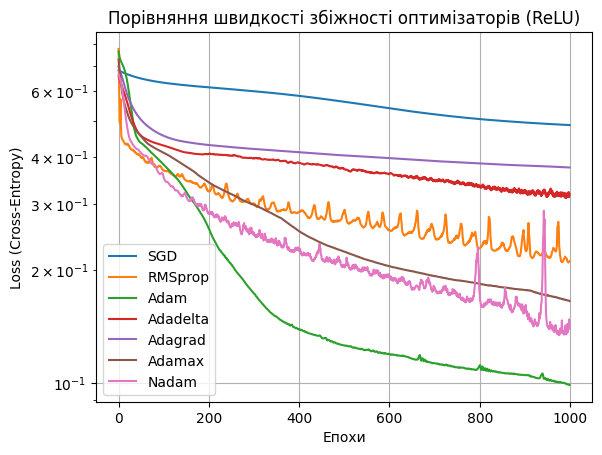

Optimizer: SGD, Function: Sigmoid, Epoch [50/1000], Train Loss: 0.6483, Validation Loss: 0.6645, Acc: 0.6209150552749634
--- [INFO] Early stopping triggered at epoch 88 for SGD ---
Optimizer: RMSprop, Function: Sigmoid, Epoch [50/1000], Train Loss: 0.4454, Validation Loss: 0.4572, Acc: 0.7647058963775635
--- [INFO] Early stopping triggered at epoch 59 for RMSprop ---
--- [INFO] Early stopping triggered at epoch 15 for Adam ---
Optimizer: Adadelta, Function: Sigmoid, Epoch [50/1000], Train Loss: 0.6350, Validation Loss: 0.6579, Acc: 0.6209150552749634
Optimizer: Adadelta, Function: Sigmoid, Epoch [100/1000], Train Loss: 0.6001, Validation Loss: 0.6104, Acc: 0.6209150552749634
Optimizer: Adadelta, Function: Sigmoid, Epoch [150/1000], Train Loss: 0.4959, Validation Loss: 0.4675, Acc: 0.7777777910232544
--- [INFO] Early stopping triggered at epoch 198 for Adadelta ---
Optimizer: Adagrad, Function: Sigmoid, Epoch [50/1000], Train Loss: 0.6135, Validation Loss: 0.6283, Acc: 0.620915055274963

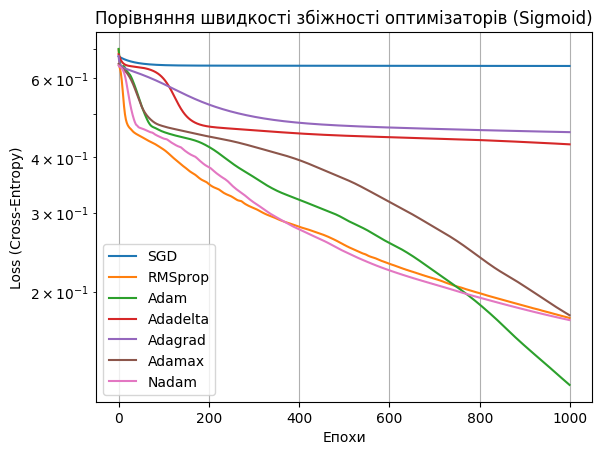

Optimizer: SGD, Function: Tanh, Epoch [50/1000], Train Loss: 0.6209, Validation Loss: 0.6298, Acc: 0.6274510025978088
Optimizer: SGD, Function: Tanh, Epoch [100/1000], Train Loss: 0.6020, Validation Loss: 0.6114, Acc: 0.6405228972434998
Optimizer: SGD, Function: Tanh, Epoch [150/1000], Train Loss: 0.5871, Validation Loss: 0.5952, Acc: 0.6535947918891907
Optimizer: SGD, Function: Tanh, Epoch [200/1000], Train Loss: 0.5740, Validation Loss: 0.5796, Acc: 0.6993464231491089
Optimizer: SGD, Function: Tanh, Epoch [250/1000], Train Loss: 0.5619, Validation Loss: 0.5642, Acc: 0.7189542651176453
Optimizer: SGD, Function: Tanh, Epoch [300/1000], Train Loss: 0.5506, Validation Loss: 0.5492, Acc: 0.7320261597633362
Optimizer: SGD, Function: Tanh, Epoch [350/1000], Train Loss: 0.5402, Validation Loss: 0.5351, Acc: 0.7320261597633362
Optimizer: SGD, Function: Tanh, Epoch [400/1000], Train Loss: 0.5308, Validation Loss: 0.5221, Acc: 0.7254902124404907
Optimizer: SGD, Function: Tanh, Epoch [450/1000],

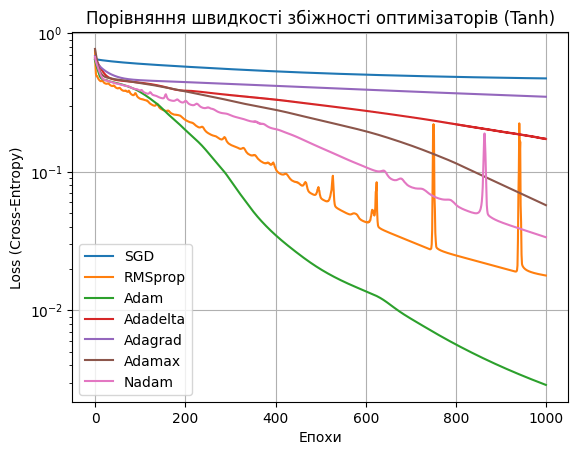

In [12]:
for activation_function_name in activation_function_names:
    for optimizer in optimizer_names:
        train_loss_history, val_loss_history, final_metrics, model = perform_learning(1000, optimizer, activation_function_name)
        current_f1 = final_metrics["f1"].item()
        if(current_f1 > best_f1):
            best_model = model
            best_f1 = current_f1
        plt.plot(train_loss_history, label=optimizer)
        
        results.append({
            'Activation': activation_function_name,
            'Optimizer': optimizer,
            'Accuracy': final_metrics['accuracy'].item(),
            'Precision': final_metrics['precision'].item(),
            'Recall': final_metrics['recall'].item(),
            'F1-Score': final_metrics['f1'].item()
        })
    plt.title(f'Порівняння швидкості збіжності оптимізаторів ({activation_function_name})')
    plt.xlabel('Епохи')
    plt.ylabel('Loss (Cross-Entropy)')
    plt.yscale('log')  
    plt.legend()
    plt.grid(True)
    plt.show()

In [13]:
results_df = pd.DataFrame(results)
print(results_df.sort_values(by='F1-Score', ascending=False))

   Activation Optimizer  Accuracy  Precision    Recall  F1-Score
13    Sigmoid     Nadam  0.816993   0.840909  0.637931  0.725490
12    Sigmoid    Adamax  0.803922   0.791667  0.655172  0.716981
11    Sigmoid   Adagrad  0.810458   0.853659  0.603448  0.707071
8     Sigmoid   RMSprop  0.797386   0.787234  0.637931  0.704762
2        ReLU      Adam  0.803922   0.868421  0.568965  0.687500
18       Tanh   Adagrad  0.803922   0.868421  0.568965  0.687500
5        ReLU    Adamax  0.784314   0.777778  0.603448  0.679612
16       Tanh      Adam  0.790850   0.825000  0.568965  0.673469
4        ReLU   Adagrad  0.790850   0.825000  0.568965  0.673469
20       Tanh     Nadam  0.784314   0.790698  0.586207  0.673267
6        ReLU     Nadam  0.784314   0.790698  0.586207  0.673267
1        ReLU   RMSprop  0.784314   0.804878  0.568965  0.666667
17       Tanh  Adadelta  0.790850   0.842105  0.551724  0.666667
19       Tanh    Adamax  0.797386   0.885714  0.534483  0.666667
3        ReLU  Adadelta  

In [14]:
def perform_learning_analysis(epochs, optimizer_name, activation_function_name):
    train_loss_history, val_loss_history, _, _ = perform_learning(epochs, optimizer_name, activation_function_name)
    plt.figure(figsize=(10, 6))
    plt.plot(train_loss_history, label='Train Loss')
    plt.plot(val_loss_history, label='Validation Loss', linestyle='--')
    plt.title(f'Аналіз перенавчання ({optimizer_name} + {activation_function_name})')
    plt.xlabel('Епохи')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

Optimizer: SGD, Function: ReLU, Epoch [50/1000], Train Loss: 0.6400, Validation Loss: 0.6427, Acc: 0.6405228972434998
Optimizer: SGD, Function: ReLU, Epoch [100/1000], Train Loss: 0.6269, Validation Loss: 0.6331, Acc: 0.6274510025978088
Optimizer: SGD, Function: ReLU, Epoch [150/1000], Train Loss: 0.6177, Validation Loss: 0.6255, Acc: 0.6209150552749634
Optimizer: SGD, Function: ReLU, Epoch [200/1000], Train Loss: 0.6098, Validation Loss: 0.6174, Acc: 0.6274510025978088
Optimizer: SGD, Function: ReLU, Epoch [250/1000], Train Loss: 0.6019, Validation Loss: 0.6084, Acc: 0.6274510025978088
Optimizer: SGD, Function: ReLU, Epoch [300/1000], Train Loss: 0.5935, Validation Loss: 0.5979, Acc: 0.6405228972434998
Optimizer: SGD, Function: ReLU, Epoch [350/1000], Train Loss: 0.5847, Validation Loss: 0.5865, Acc: 0.6601307392120361
Optimizer: SGD, Function: ReLU, Epoch [400/1000], Train Loss: 0.5753, Validation Loss: 0.5742, Acc: 0.6928104758262634
Optimizer: SGD, Function: ReLU, Epoch [450/1000],

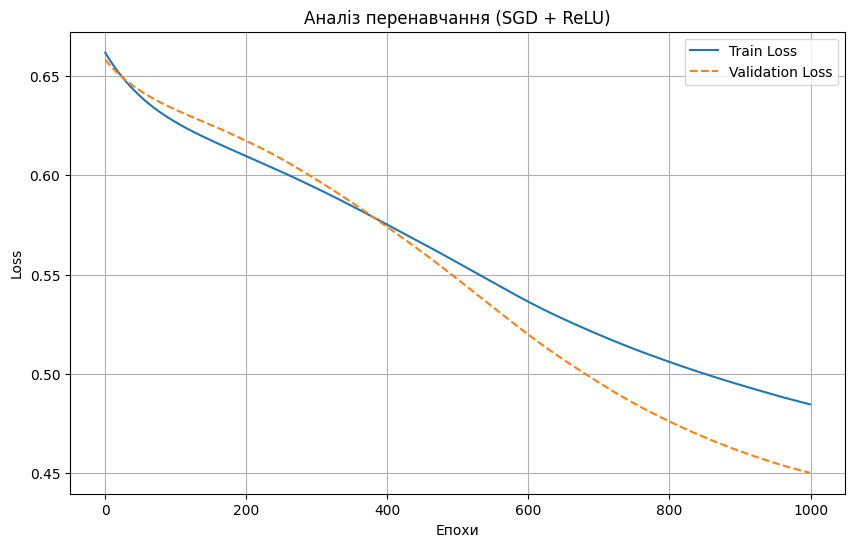

--- [INFO] Early stopping triggered at epoch 17 for RMSprop ---


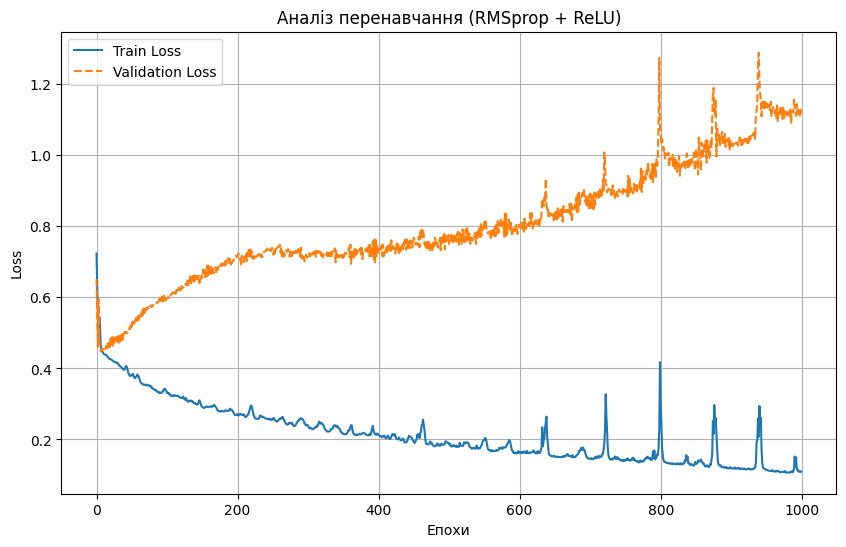

--- [INFO] Early stopping triggered at epoch 40 for Adam ---


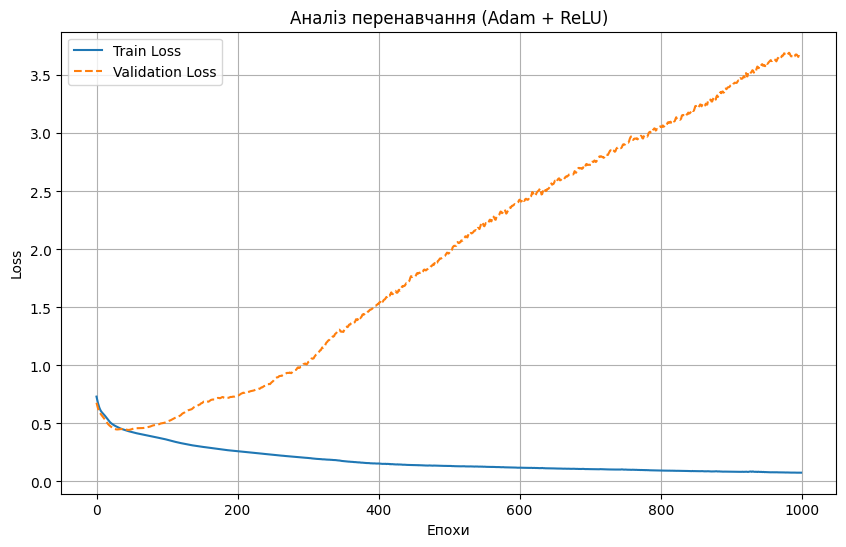

Optimizer: Adadelta, Function: ReLU, Epoch [50/1000], Train Loss: 0.4725, Validation Loss: 0.4660, Acc: 0.7908496856689453
--- [INFO] Early stopping triggered at epoch 69 for Adadelta ---


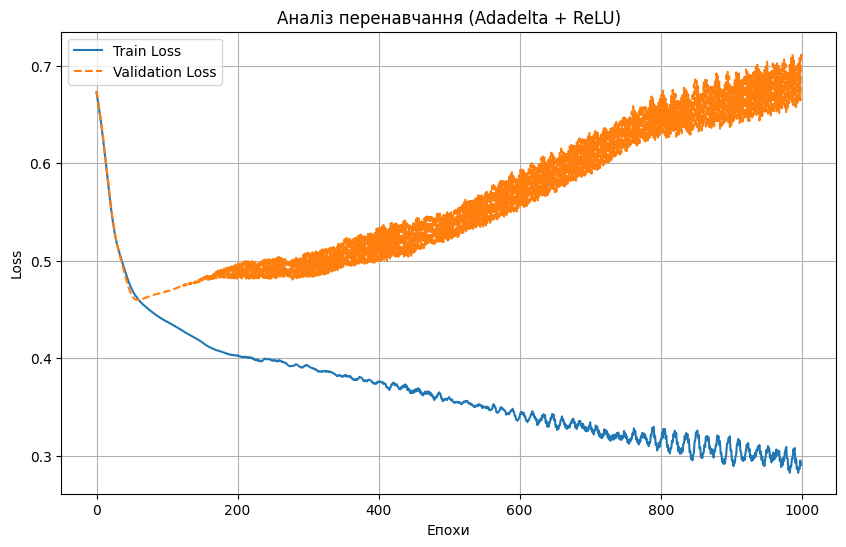

Optimizer: Adagrad, Function: ReLU, Epoch [50/1000], Train Loss: 0.4866, Validation Loss: 0.4588, Acc: 0.7908496856689453
Optimizer: Adagrad, Function: ReLU, Epoch [100/1000], Train Loss: 0.4463, Validation Loss: 0.4314, Acc: 0.8235294222831726
--- [INFO] Early stopping triggered at epoch 104 for Adagrad ---


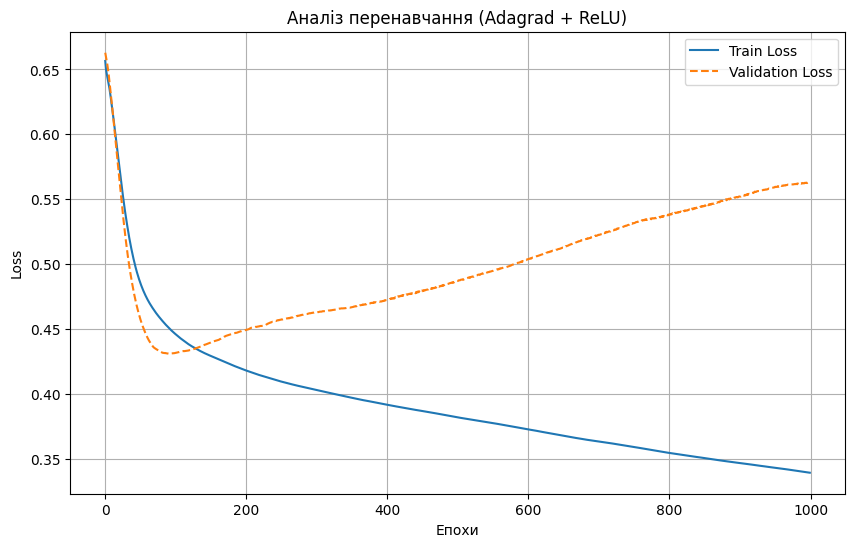

--- [INFO] Early stopping triggered at epoch 39 for Adamax ---


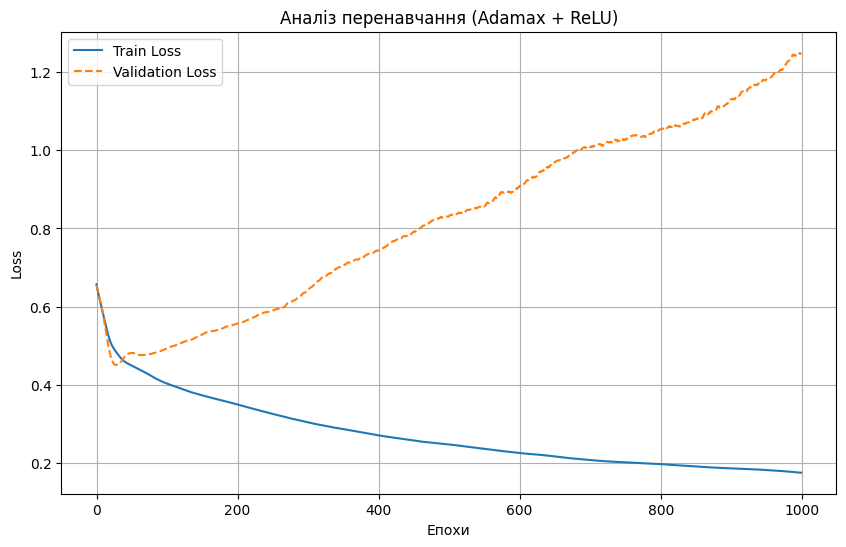

--- [INFO] Early stopping triggered at epoch 32 for Nadam ---


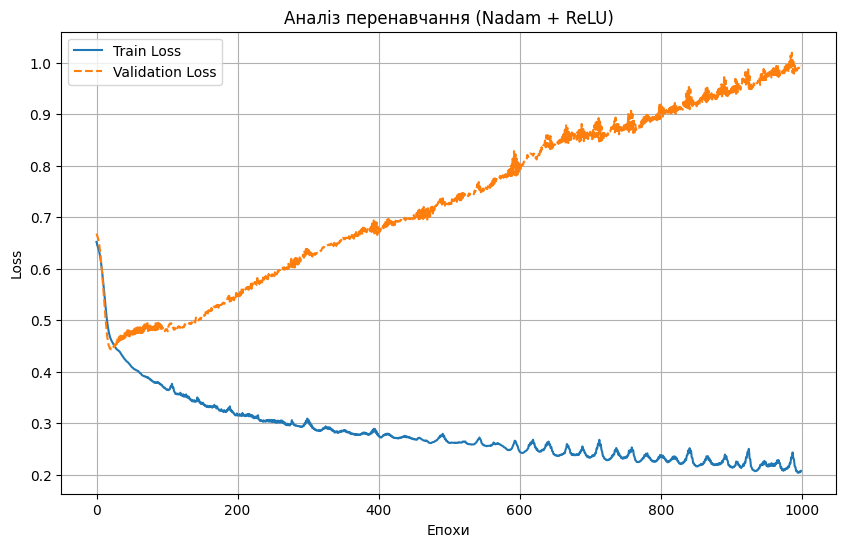

Optimizer: SGD, Function: Sigmoid, Epoch [50/1000], Train Loss: 0.6748, Validation Loss: 0.6773, Acc: 0.6209150552749634
Optimizer: SGD, Function: Sigmoid, Epoch [100/1000], Train Loss: 0.6492, Validation Loss: 0.6625, Acc: 0.6209150552749634
--- [INFO] Early stopping triggered at epoch 148 for SGD ---


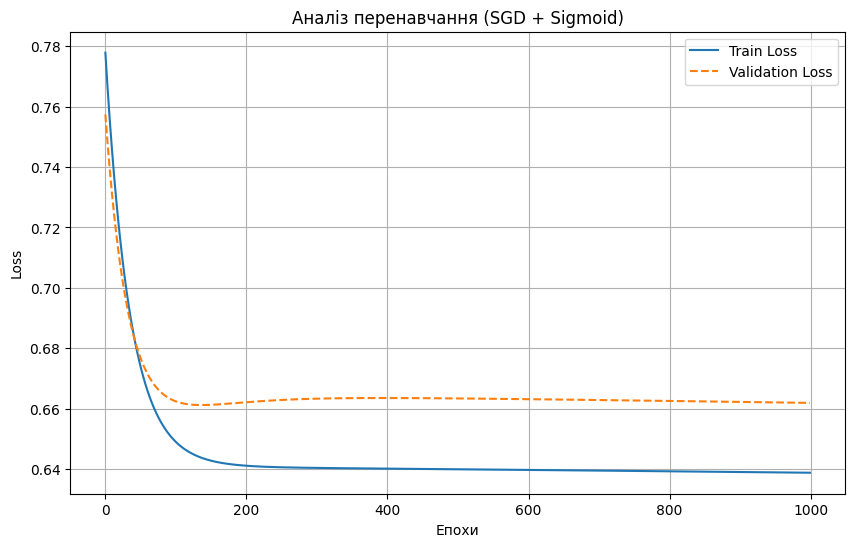

--- [INFO] Early stopping triggered at epoch 39 for RMSprop ---


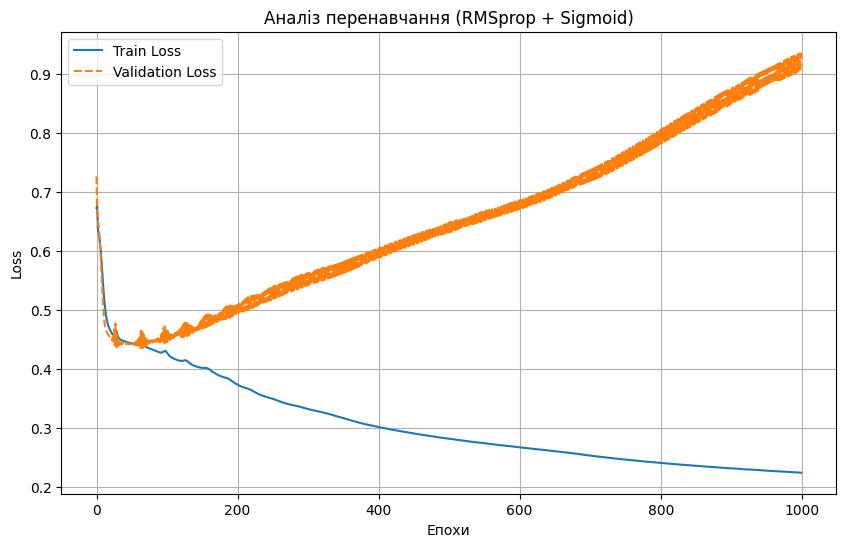

--- [INFO] Early stopping triggered at epoch 14 for Adam ---


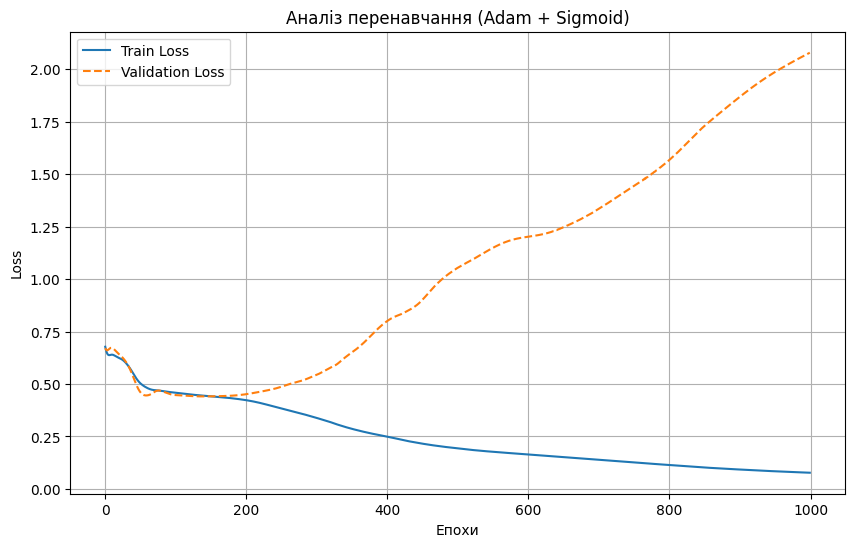

Optimizer: Adadelta, Function: Sigmoid, Epoch [50/1000], Train Loss: 0.6366, Validation Loss: 0.6597, Acc: 0.6209150552749634
Optimizer: Adadelta, Function: Sigmoid, Epoch [100/1000], Train Loss: 0.6141, Validation Loss: 0.6303, Acc: 0.6209150552749634
Optimizer: Adadelta, Function: Sigmoid, Epoch [150/1000], Train Loss: 0.5213, Validation Loss: 0.5039, Acc: 0.7516340017318726
Optimizer: Adadelta, Function: Sigmoid, Epoch [200/1000], Train Loss: 0.4739, Validation Loss: 0.4439, Acc: 0.8104575276374817
--- [INFO] Early stopping triggered at epoch 232 for Adadelta ---


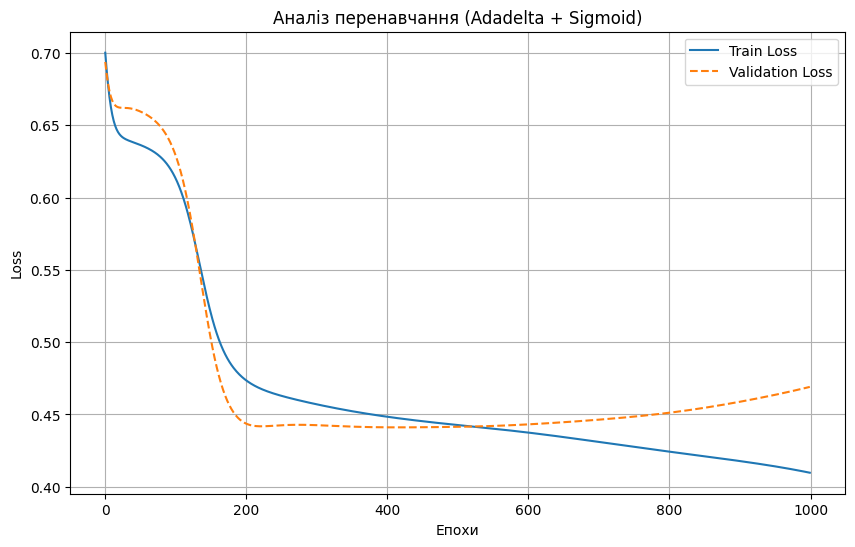

Optimizer: Adagrad, Function: Sigmoid, Epoch [50/1000], Train Loss: 0.6261, Validation Loss: 0.6448, Acc: 0.6209150552749634
Optimizer: Adagrad, Function: Sigmoid, Epoch [100/1000], Train Loss: 0.5882, Validation Loss: 0.5894, Acc: 0.6209150552749634
Optimizer: Adagrad, Function: Sigmoid, Epoch [150/1000], Train Loss: 0.5500, Validation Loss: 0.5327, Acc: 0.7647058963775635
Optimizer: Adagrad, Function: Sigmoid, Epoch [200/1000], Train Loss: 0.5228, Validation Loss: 0.4945, Acc: 0.7516340017318726
Optimizer: Adagrad, Function: Sigmoid, Epoch [250/1000], Train Loss: 0.5039, Validation Loss: 0.4726, Acc: 0.7516340017318726
Optimizer: Adagrad, Function: Sigmoid, Epoch [300/1000], Train Loss: 0.4902, Validation Loss: 0.4609, Acc: 0.7777777910232544
Optimizer: Adagrad, Function: Sigmoid, Epoch [350/1000], Train Loss: 0.4805, Validation Loss: 0.4551, Acc: 0.7843137383460999
Optimizer: Adagrad, Function: Sigmoid, Epoch [400/1000], Train Loss: 0.4737, Validation Loss: 0.4522, Acc: 0.7908496856

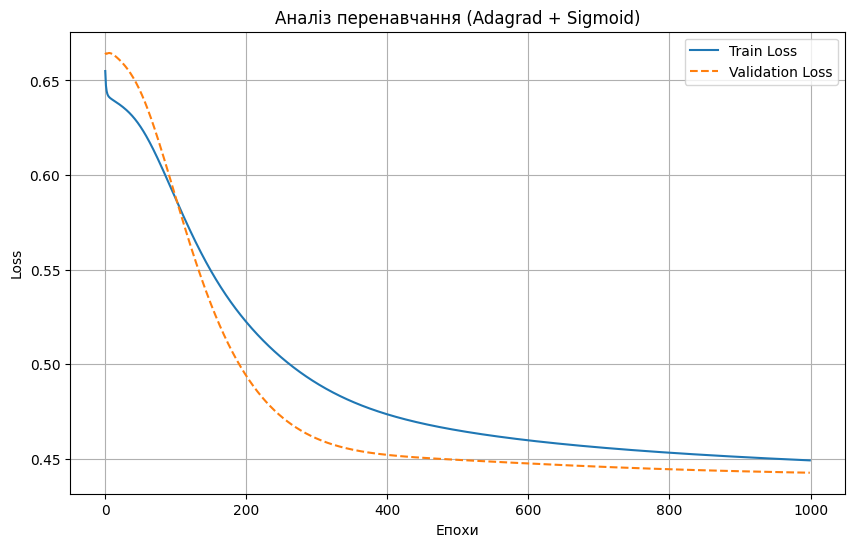

Optimizer: Adamax, Function: Sigmoid, Epoch [50/1000], Train Loss: 0.5133, Validation Loss: 0.4650, Acc: 0.7712418437004089
--- [INFO] Early stopping triggered at epoch 75 for Adamax ---


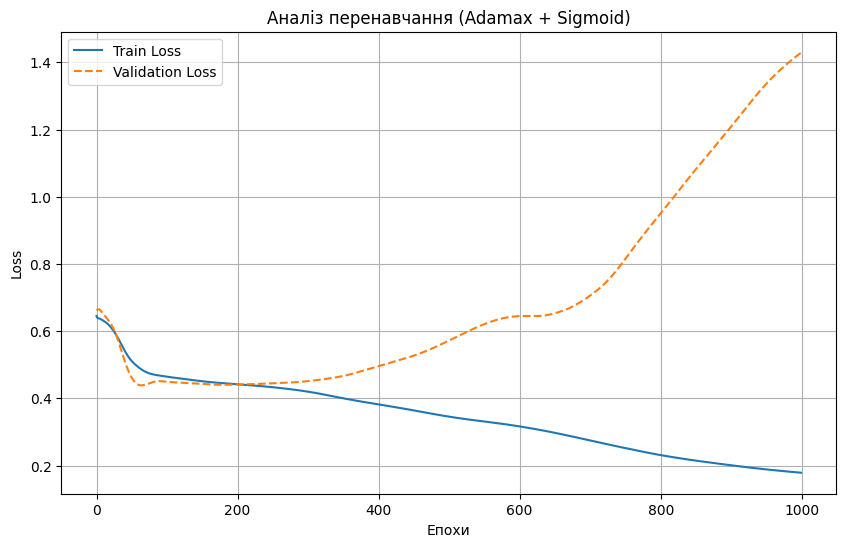

Optimizer: Nadam, Function: Sigmoid, Epoch [50/1000], Train Loss: 0.5797, Validation Loss: 0.5771, Acc: 0.6209150552749634
Optimizer: Nadam, Function: Sigmoid, Epoch [100/1000], Train Loss: 0.4645, Validation Loss: 0.4614, Acc: 0.7973856329917908
Optimizer: Nadam, Function: Sigmoid, Epoch [150/1000], Train Loss: 0.4457, Validation Loss: 0.4510, Acc: 0.7908496856689453
Optimizer: Nadam, Function: Sigmoid, Epoch [200/1000], Train Loss: 0.4257, Validation Loss: 0.4467, Acc: 0.7973856329917908
--- [INFO] Early stopping triggered at epoch 243 for Nadam ---


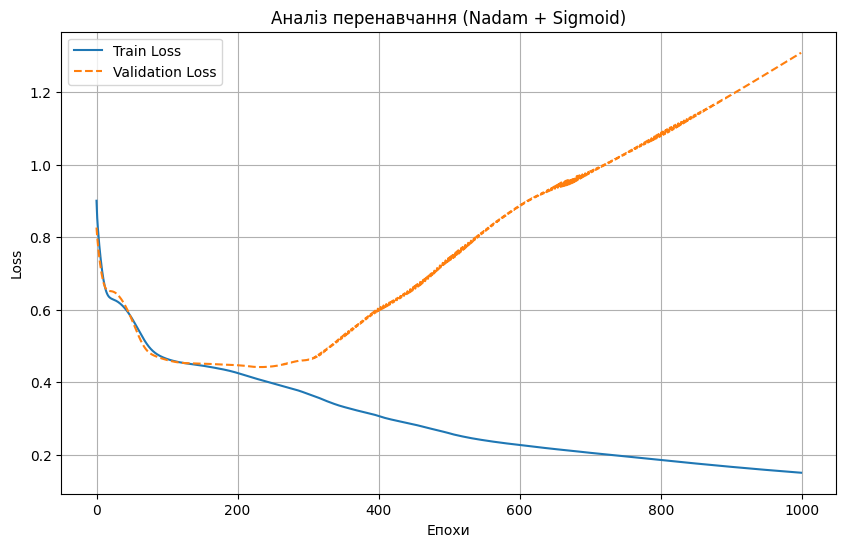

Optimizer: SGD, Function: Tanh, Epoch [50/1000], Train Loss: 0.6318, Validation Loss: 0.6227, Acc: 0.6928104758262634
Optimizer: SGD, Function: Tanh, Epoch [100/1000], Train Loss: 0.6122, Validation Loss: 0.6022, Acc: 0.7058823704719543
Optimizer: SGD, Function: Tanh, Epoch [150/1000], Train Loss: 0.5974, Validation Loss: 0.5853, Acc: 0.6928104758262634
Optimizer: SGD, Function: Tanh, Epoch [200/1000], Train Loss: 0.5851, Validation Loss: 0.5701, Acc: 0.7124183177947998
Optimizer: SGD, Function: Tanh, Epoch [250/1000], Train Loss: 0.5743, Validation Loss: 0.5560, Acc: 0.7254902124404907
Optimizer: SGD, Function: Tanh, Epoch [300/1000], Train Loss: 0.5645, Validation Loss: 0.5428, Acc: 0.7516340017318726
Optimizer: SGD, Function: Tanh, Epoch [350/1000], Train Loss: 0.5557, Validation Loss: 0.5304, Acc: 0.7385621070861816
Optimizer: SGD, Function: Tanh, Epoch [400/1000], Train Loss: 0.5475, Validation Loss: 0.5189, Acc: 0.758169949054718
Optimizer: SGD, Function: Tanh, Epoch [450/1000], 

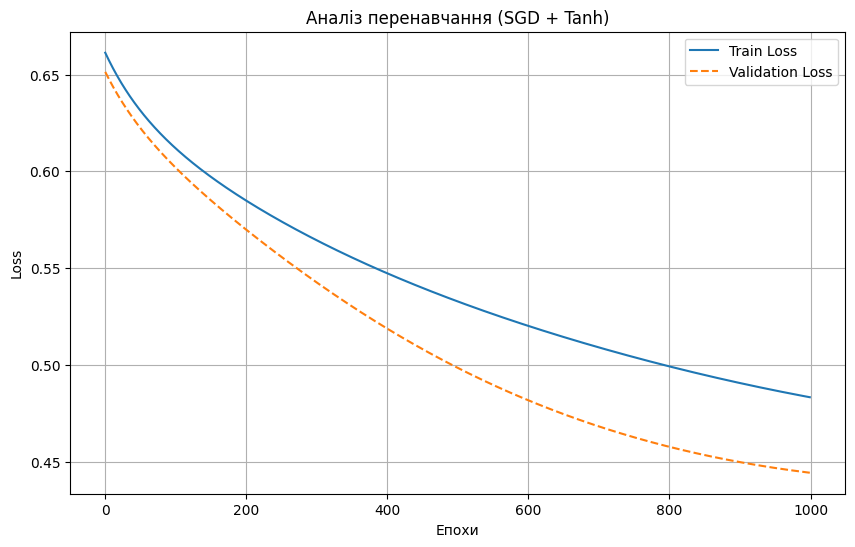

--- [INFO] Early stopping triggered at epoch 12 for RMSprop ---


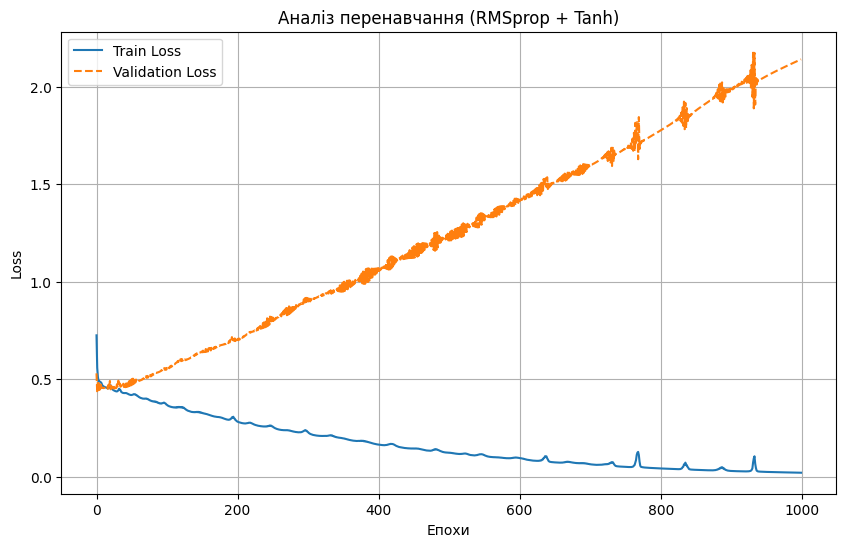

--- [INFO] Early stopping triggered at epoch 28 for Adam ---


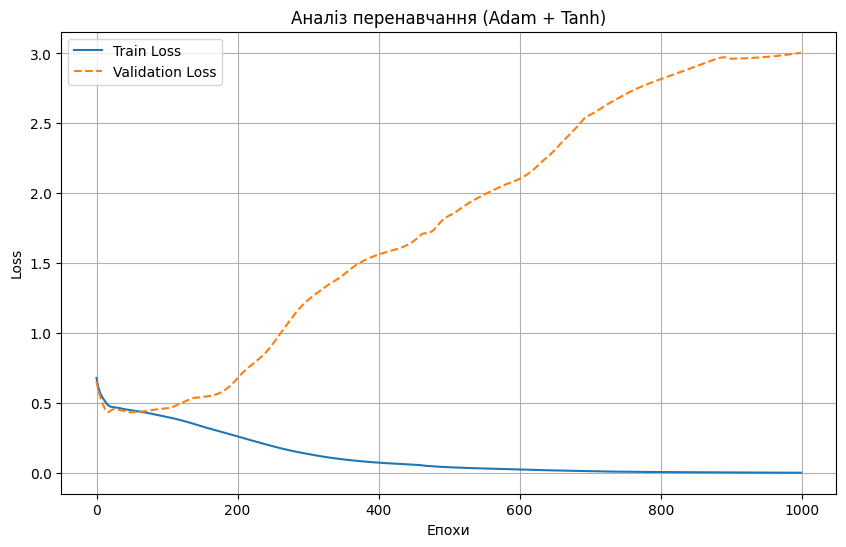

Optimizer: Adadelta, Function: Tanh, Epoch [50/1000], Train Loss: 0.4632, Validation Loss: 0.4528, Acc: 0.8300653696060181
--- [INFO] Early stopping triggered at epoch 94 for Adadelta ---


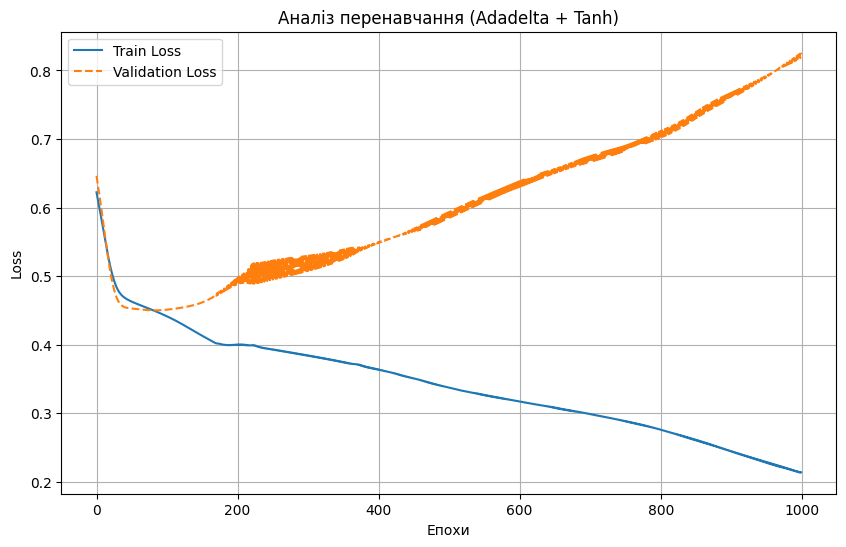

Optimizer: Adagrad, Function: Tanh, Epoch [50/1000], Train Loss: 0.4862, Validation Loss: 0.4533, Acc: 0.7843137383460999
--- [INFO] Early stopping triggered at epoch 80 for Adagrad ---


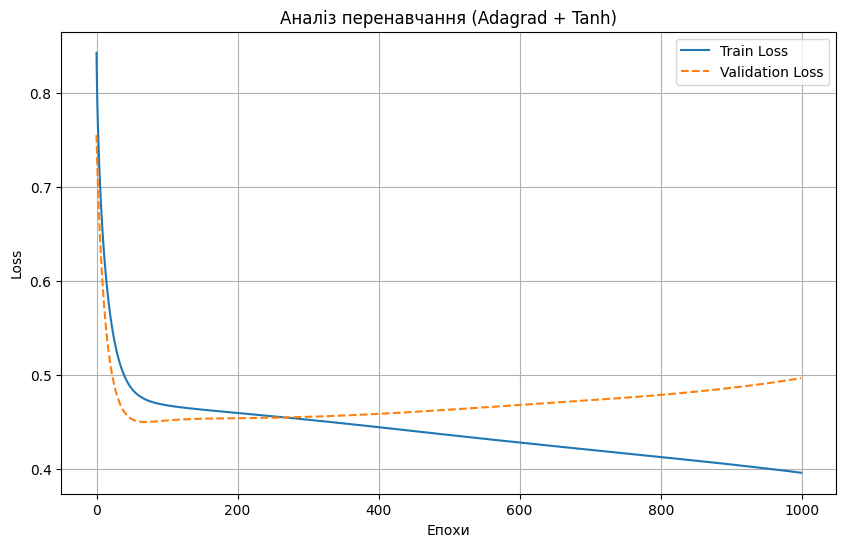

--- [INFO] Early stopping triggered at epoch 34 for Adamax ---


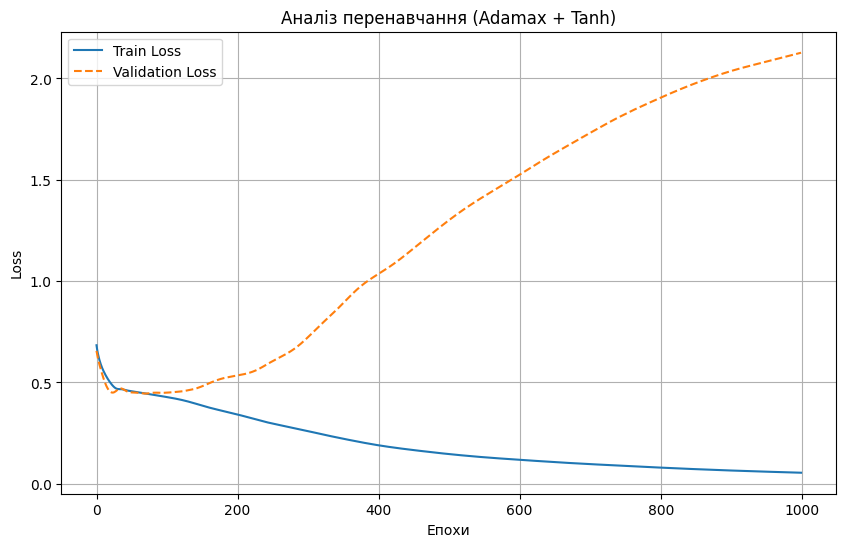

--- [INFO] Early stopping triggered at epoch 26 for Nadam ---


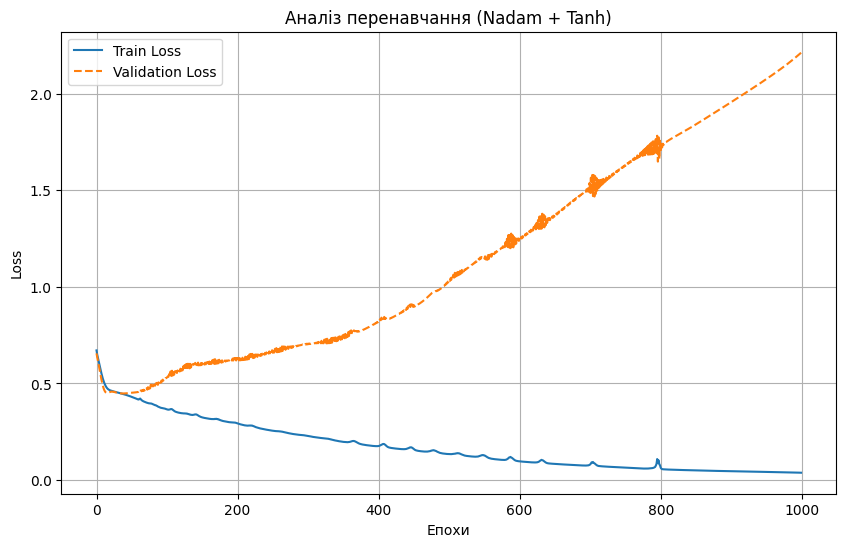

In [15]:
for activation_function_name in activation_function_names:
    for optimizer in optimizer_names:
        perform_learning_analysis(1000, optimizer, activation_function_name)
        

In [16]:
print("\n" + "="*30)
print("ФІНАЛЬНІ РЕЗУЛЬТАТИ НА ТЕСТОВІЙ ВИБІРЦІ (Diabetes)")
best_model.eval()
with torch.no_grad():
    test_logits = best_model(X_test_scaled_tensor)
    _, test_predictions = torch.max(test_logits, 1)

from sklearn.metrics import classification_report
print(classification_report(y_test_tensor.squeeze().long(), test_predictions))


ФІНАЛЬНІ РЕЗУЛЬТАТИ НА ТЕСТОВІЙ ВИБІРЦІ (Wages)
              precision    recall  f1-score   support

           0       0.78      0.70      0.74        50
           1       0.53      0.63      0.58        27

    accuracy                           0.68        77
   macro avg       0.65      0.66      0.66        77
weighted avg       0.69      0.68      0.68        77



In [18]:
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [21]:
classic_classifiers = {
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=100, random_state=42),
    'LogisticRegression': LogisticRegression(random_state=42)
}

print("\nНавчання класичних класифікаторів...")

for name, model in classic_classifiers.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_val_scaled)
    
    acc = accuracy_score(y_val, predictions)
    prec = precision_score(y_val, predictions)
    rec = recall_score(y_val, predictions)
    f1 = f1_score(y_val, predictions)
    
    results.append({
        'Activation': 'Classical ML',
        'Optimizer': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })
    print(f"{name} завершено. F1-Score: {f1:.4f}")

results_df = pd.DataFrame(results)
print("\nФІНАЛЬНЕ ПОРІВНЯННЯ ВСІХ МОДЕЛЕЙ (MLP vs Classical ML):")
print(results_df.sort_values(by='F1-Score', ascending=False))


Навчання класичних класифікаторів...
XGBoost завершено. F1-Score: 0.6604
RandomForest завершено. F1-Score: 0.6465
LogisticRegression завершено. F1-Score: 0.6522

ФІНАЛЬНЕ ПОРІВНЯННЯ ВСІХ МОДЕЛЕЙ (MLP vs Classical ML):
      Activation           Optimizer  Accuracy  Precision    Recall  F1-Score
13       Sigmoid               Nadam  0.816993   0.840909  0.637931  0.725490
12       Sigmoid              Adamax  0.803922   0.791667  0.655172  0.716981
11       Sigmoid             Adagrad  0.810458   0.853659  0.603448  0.707071
8        Sigmoid             RMSprop  0.797386   0.787234  0.637931  0.704762
18          Tanh             Adagrad  0.803922   0.868421  0.568965  0.687500
2           ReLU                Adam  0.803922   0.868421  0.568965  0.687500
5           ReLU              Adamax  0.784314   0.777778  0.603448  0.679612
4           ReLU             Adagrad  0.790850   0.825000  0.568965  0.673469
16          Tanh                Adam  0.790850   0.825000  0.568965  0.673469
2